# Stage 3: Glucose Variability (Participant 001)

Stage 2 described the overall *level* of glucose. Here we look at how much and how fast it *moves*.

| # | Question |
|---|---|
| Q1 | What are the standard deviation and CV? Is glucose stable (CV < 36%)? |
| Q2 | How fast does glucose change between consecutive readings? |
| Q3 | What are the largest rises and falls, and when did they happen? |

## Setup

We load the cleaned file from Stage 1 (or fall back to the raw Dexcom file).

`WINDOW_MIN` sets the time window used in Q3 to find large rises and falls. 60 minutes captures most meal responses; try 30 for faster events.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
RAW_PATH = f"{DATA_DIR}/{PID}/Dexcom_{PID}.csv"
DEMO_PATH = f"{DATA_DIR}/Demographics.csv"

INTERVAL = pd.Timedelta("5min")
WINDOW_MIN = 60   # window for Q3 (minutes)
TOP_N = 5         # how many rises/falls to list

In [2]:
if os.path.exists(CLEAN_PATH):
    glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"])
    print("Loaded cleaned file from Stage 1")
else:
    raw = pd.read_csv(RAW_PATH, skiprows=range(1, 13))
    raw = raw[raw["Event Type"] == "EGV"]
    glu = pd.DataFrame({
        "timestamp": pd.to_datetime(raw["Timestamp (YYYY-MM-DDThh:mm:ss)"]),
        "glucose": pd.to_numeric(raw["Glucose Value (mg/dL)"], errors="coerce"),
    }).dropna().drop_duplicates("timestamp")
    print("Stage 1 file not found, loaded raw Dexcom file instead")

glu = glu.sort_values("timestamp").reset_index(drop=True)
g = glu["glucose"]
print("Readings:", len(g))

Loaded cleaned file from Stage 1
Readings: 2561


In [4]:
glu["timestamp"]

0      2020-02-13 17:23:32
1      2020-02-13 17:28:32
2      2020-02-13 17:33:32
3      2020-02-13 17:38:32
4      2020-02-13 17:43:31
               ...        
2556   2020-02-22 17:33:23
2557   2020-02-22 17:38:23
2558   2020-02-22 17:43:23
2559   2020-02-22 17:48:22
2560   2020-02-22 17:53:23
Name: timestamp, Length: 2561, dtype: datetime64[us]

### Put readings on a regular 5-minute grid

To compare a reading with the one 5 or 60 minutes later, we place each reading in its 5-minute slot counted from the first reading. Missing readings become `NaN` slots, so any change across a gap is automatically excluded instead of being counted as one big jump.

In [3]:
start = glu["timestamp"].iloc[0]
glu["slot"] = ((glu["timestamp"] - start) / INTERVAL).round().astype(int)

grid = (
    glu.drop_duplicates("slot")
    .set_index("slot")["glucose"]
    .reindex(range(glu["slot"].max() + 1))
)
grid.index = start + grid.index * INTERVAL
grid.index.name = "timestamp"

print("Grid slots:", len(grid), "| missing:", grid.isna().sum())

Grid slots: 2599 | missing: 38


In [6]:
grid

timestamp
2020-02-13 17:23:32     61.0
2020-02-13 17:28:32     59.0
2020-02-13 17:33:32     58.0
2020-02-13 17:38:32     59.0
2020-02-13 17:43:32     63.0
                       ...  
2020-02-22 17:33:32    139.0
2020-02-22 17:38:32    141.0
2020-02-22 17:43:32    143.0
2020-02-22 17:48:32    139.0
2020-02-22 17:53:32    129.0
Name: glucose, Length: 2599, dtype: float64

---
## Q1: Standard deviation and coefficient of variation (CV)

- **SD** is the typical distance of readings from the mean, in mg/dL.
- **CV** = SD ÷ mean × 100. Because it is relative to the mean, it allows comparison between people with different average levels.

The international CGM consensus uses **CV < 36%** as the threshold for stable glucose. That threshold was set for people with diabetes, so people without diabetes usually sit well below it. Comparing participants with each other is often more informative in this dataset.

In [25]:
sd = g.std()
mean = g.mean()
cv = sd / mean * 100

print(f"Mean: {mean:.1f} mg/dL")
print(f"SD:   {sd:.1f} mg/dL")
print(f"CV:   {cv:.1f} %  →  {'stable (< 36%)' if cv < 36 else 'unstable (≥ 36%)'}")

Mean: 106.1 mg/dL
SD:   15.8 mg/dL
CV:   14.9 %  →  stable (< 36%)


### Variability per day

The overall CV mixes together differences *within* a day (meals, activity) and differences *between* days. Looking at each day separately shows whether some days were much more variable than others.

In [26]:
daily = glu.groupby(glu["timestamp"].dt.date.rename("date"))["glucose"].agg(["count", "mean", "std", "min", "max"])
daily["CV %"] = daily["std"] / daily["mean"] * 100
daily["range"] = daily["max"] - daily["min"]
daily = daily.round(1)
daily

,count,mean,std,min,max,CV %,range
date,,,,,,,
2020-02-13,80,101.4,20.7,58.0,143.0,20.4,85.0
2020-02-14,288,100.0,15.5,66.0,146.0,15.5,80.0
2020-02-15,287,93.5,9.4,62.0,122.0,10.1,60.0
2020-02-16,288,104.1,14.4,46.0,142.0,13.8,96.0
2020-02-17,288,101.8,16.2,78.0,152.0,15.9,74.0
2020-02-18,288,111.6,12.7,74.0,141.0,11.3,67.0
2020-02-19,284,120.3,12.8,99.0,155.0,10.6,56.0
2020-02-20,255,110.0,15.3,76.0,148.0,13.9,72.0
2020-02-21,288,110.8,12.1,87.0,142.0,10.9,55.0


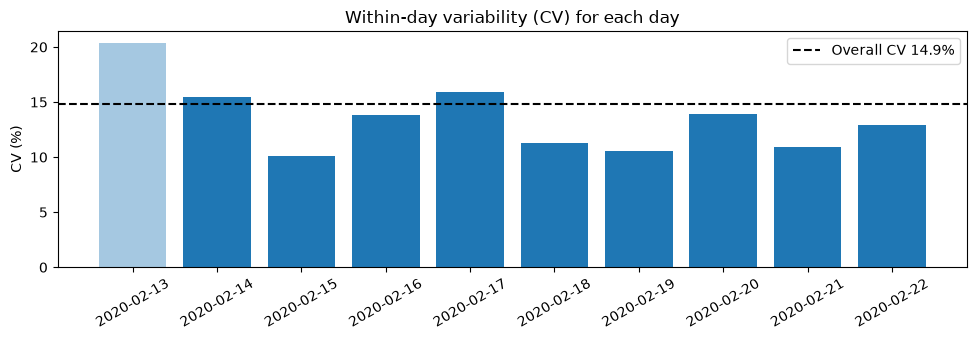

In [27]:
fig, ax = plt.subplots(figsize=(10, 3.5))
bars = ax.bar(daily.index.astype(str), daily["CV %"], color="tab:blue")
ax.axhline(cv, color="black", ls="--", label=f"Overall CV {cv:.1f}%")
ax.set_ylabel("CV (%)")
ax.set_title("Within-day variability (CV) for each day")
ax.legend()

# Partial days (fewer than half the readings) are drawn lighter
for bar, n in zip(bars, daily["count"]):
    if n < 144:
        bar.set_alpha(0.4)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
# Split the total SD into within-day and between-day parts
within_day_sd = glu.groupby(glu["timestamp"].dt.date)["glucose"].std().mean()
between_day_sd = daily["mean"].std()

print(f"Average within-day SD:     {within_day_sd:.1f} mg/dL")
print(f"SD of daily means:         {between_day_sd:.1f} mg/dL")
print("→ Most variability comes from",
      "changes within each day" if within_day_sd > between_day_sd else "differences between days")

Average within-day SD:     14.2 mg/dL
SD of daily means:         7.5 mg/dL
→ Most variability comes from changes within each day


---
## Q2: How fast does glucose change?

The **rate of change** is the difference between consecutive readings divided by 5 minutes (mg/dL per minute).

Dexcom shows this as trend arrows, which give a handy way to group the rates:

| Arrow | Rate (mg/dL/min) | Meaning |
|---|---|---|
| → | −1 to 1 | Steady |
| ↗ / ↘ | 1–2 | Slowly rising / falling |
| ↑ / ↓ | 2–3 | Rising / falling |
| ⇈ / ⇊ | > 3 | Rapidly rising / falling |

In [13]:
rate = grid.diff() / 5   # mg/dL per minute, NaN across gaps
rate = rate.dropna()

print("Rate of change (mg/dL/min):")
print(rate.describe().round(2).to_string())
print(f"\nMean absolute rate: {rate.abs().mean():.2f} mg/dL/min")
print(f"95% of changes are within ±{rate.abs().quantile(0.95):.2f} mg/dL/min")

Rate of change (mg/dL/min):
count    2558.00
mean        0.00
std         0.67
min        -4.20
25%        -0.20
50%         0.00
75%         0.20
max         3.80

Mean absolute rate: 0.43 mg/dL/min
95% of changes are within ±1.60 mg/dL/min


In [30]:
grid

timestamp
2020-02-13 17:23:32     61.0
2020-02-13 17:28:32     59.0
2020-02-13 17:33:32     58.0
2020-02-13 17:38:32     59.0
2020-02-13 17:43:32     63.0
                       ...  
2020-02-22 17:33:32    139.0
2020-02-22 17:38:32    141.0
2020-02-22 17:43:32    143.0
2020-02-22 17:48:32    139.0
2020-02-22 17:53:32    129.0
Name: glucose, Length: 2599, dtype: float64

In [32]:
glu

,timestamp,glucose,slot
0,2020-02-13 17:23:32,61.0,0
1,2020-02-13 17:28:32,59.0,1
2,2020-02-13 17:33:32,58.0,2
3,2020-02-13 17:38:32,59.0,3
4,2020-02-13 17:43:31,63.0,4
...,...,...,...
2556,2020-02-22 17:33:23,139.0,2594
2557,2020-02-22 17:38:23,141.0,2595
2558,2020-02-22 17:43:23,143.0,2596
2559,2020-02-22 17:48:22,139.0,2597


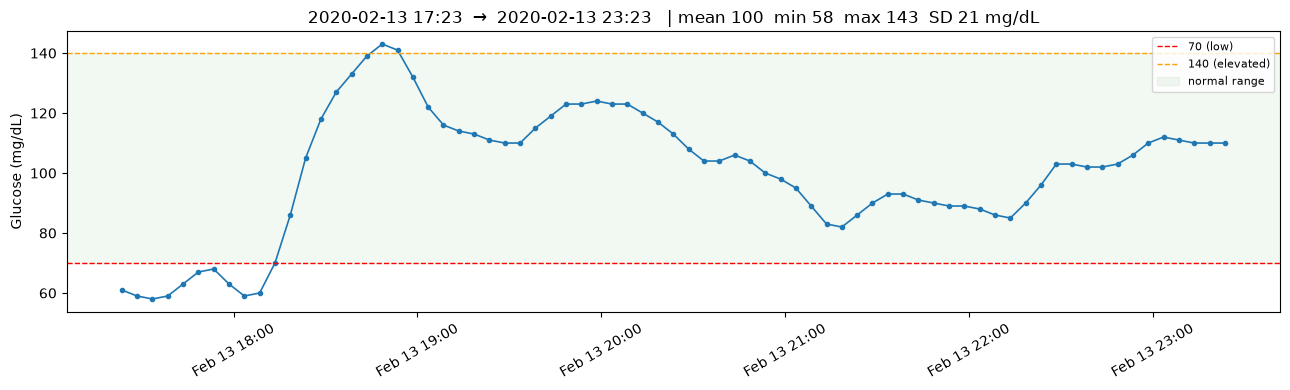

Readings in window: 73


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- settings ---
WINDOW_HOURS = 6        # how many hours to show at once
STEP_HOURS   = 3        # how many hours to jump forward/backward

# --- viewer ---
current = [grid.index[0]]      # mutable so the inner function can update it

def plot_window(start):
    end = start + pd.Timedelta(hours=WINDOW_HOURS)
    window = grid[start:end]

    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(window.index, window.values, "o-", ms=3, lw=1.2, color="tab:blue")

    # reference lines
    ax.axhline(70,  color="red",    ls="--", lw=1, label="70 (low)")
    ax.axhline(140, color="orange", ls="--", lw=1, label="140 (elevated)")
    ax.axhspan(70, 140, color="green", alpha=0.05, label="normal range")

    # stats for this window
    ax.set_title(
        f"{start:%Y-%m-%d %H:%M}  →  {end:%Y-%m-%d %H:%M}   "
        f"| mean {window.mean():.0f}  min {window.min():.0f}  "
        f"max {window.max():.0f}  SD {window.std():.0f} mg/dL"
    )
    ax.set_ylabel("Glucose (mg/dL)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d %H:%M"))
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    plt.xticks(rotation=30)
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"Readings in window: {len(window)}")

def forward():
    current[0] = min(current[0] + pd.Timedelta(hours=STEP_HOURS),
                     grid.index[-1] - pd.Timedelta(hours=WINDOW_HOURS))
    plot_window(current[0])

def backward():
    current[0] = max(current[0] - pd.Timedelta(hours=STEP_HOURS),
                     grid.index[0])
    plot_window(current[0])

def jump_to(date_str):
    """Jump to any time, e.g. jump_to('2020-02-16 07:00')"""
    current[0] = pd.Timestamp(date_str)
    plot_window(current[0])

# --- start ---
plot_window(current[0])

In [14]:
bins = [-np.inf, -3, -2, -1, 1, 2, 3, np.inf]
labels = ["⇊ < −3", "↓ −3 to −2", "↘ −2 to −1", "→ −1 to 1", "↗ 1 to 2", "↑ 2 to 3", "⇈ > 3"]
rate_cat = pd.cut(rate, bins=bins, labels=labels)

arrows = rate_cat.value_counts(sort=False).rename("readings").rename_axis("trend").to_frame()
arrows["% of time"] = (arrows["readings"] / len(rate) * 100).round(1)
arrows

,readings,% of time
trend,,
⇊ < −3,7,0.3
↓ −3 to −2,27,1.1
↘ −2 to −1,117,4.6
→ −1 to 1,2287,89.4
↗ 1 to 2,94,3.7
↑ 2 to 3,23,0.9
⇈ > 3,3,0.1


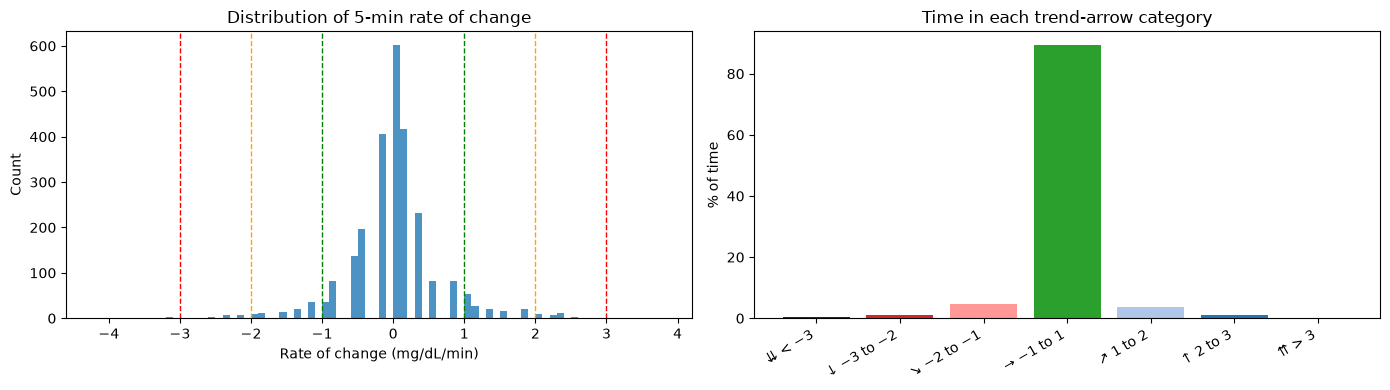

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(rate, bins=80, color="tab:blue", alpha=0.8)
for t, c in [(1, "green"), (2, "orange"), (3, "red")]:
    axes[0].axvline(t, color=c, ls="--", lw=1)
    axes[0].axvline(-t, color=c, ls="--", lw=1)
axes[0].set_xlabel("Rate of change (mg/dL/min)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of 5-min rate of change")

colors = ["#8b0000", "#d62728", "#ff9896", "#2ca02c", "#aec7e8", "#1f77b4", "#08306b"]
axes[1].bar(range(len(arrows)), arrows["% of time"], color=colors)
axes[1].set_xticks(range(len(arrows)))
axes[1].set_xticklabels(labels, rotation=30, ha="right")
axes[1].set_ylabel("% of time")
axes[1].set_title("Time in each trend-arrow category")

plt.tight_layout()
plt.show()

### When during the day does glucose move the most?

Averaging the absolute rate by hour of day shows when glucose is most dynamic. Peaks usually line up with meal times, while nights are typically calm.

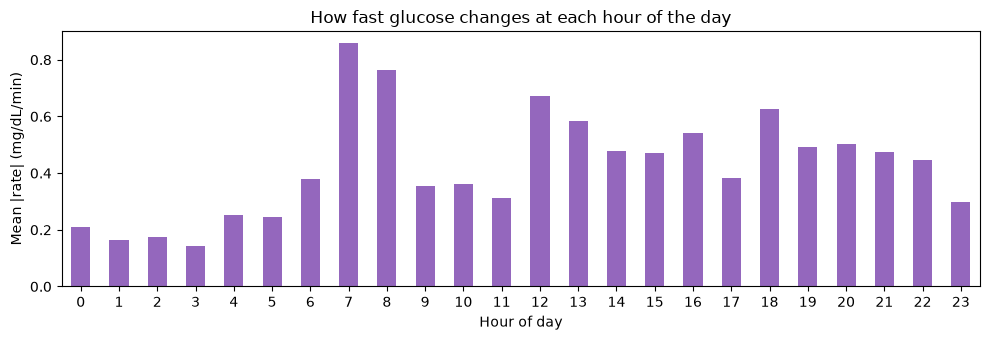

Most dynamic hours: [7, 8, 12]
Calmest hours:      [3, 1, 2]


In [34]:
hourly_rate = rate.abs().groupby(rate.index.hour).mean()

ax = hourly_rate.plot(kind="bar", figsize=(10, 3.5), color="tab:purple")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean |rate| (mg/dL/min)")
ax.set_title("How fast glucose changes at each hour of the day")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Most dynamic hours:", list(hourly_rate.nlargest(3).index))
print("Calmest hours:     ", list(hourly_rate.nsmallest(3).index))

---
## Q3: Largest rises and falls

A single 5-minute step is small and noisy, so we look at the change over a longer window (`WINDOW_MIN`, default 60 min):

change = glucose 60 min later − glucose now

We then pick the top rises and falls that **don't overlap**, so one long meal response isn't counted several times. The time of day is included so you can later match each event with the food log.

If Stage 1 flagged a sensor-noise jump, it may show up here as a sharp rise immediately followed by an equally sharp fall. Check the close-up plots and ignore such events.

In [44]:
steps = WINDOW_MIN // 5
change = (grid - grid.shift(steps)).dropna()   # change over the next WINDOW_MIN minutes
change

timestamp
2020-02-13 18:23:32    44.0
2020-02-13 18:28:32    59.0
2020-02-13 18:33:32    69.0
2020-02-13 18:38:32    74.0
2020-02-13 18:43:32    76.0
                       ... 
2020-02-22 17:33:32    16.0
2020-02-22 17:38:32    16.0
2020-02-22 17:43:32    16.0
2020-02-22 17:48:32    10.0
2020-02-22 17:53:32    -1.0
Name: glucose, Length: 2536, dtype: float64

In [17]:
steps = WINDOW_MIN // 5
change = (grid.shift(-steps) - grid).dropna()   # change over the next WINDOW_MIN minutes

def top_events(series, n, ascending):
    """Pick the n largest (or smallest) values that are at least one window apart."""
    picked = []
    for t, v in series.sort_values(ascending=ascending).items():
        if all(abs(t - p) >= pd.Timedelta(minutes=WINDOW_MIN) for p, _ in picked):
            picked.append((t, v))
        if len(picked) == n:
            break
    out = pd.DataFrame(picked, columns=["start", "change"])
    out["end"] = out["start"] + pd.Timedelta(minutes=WINDOW_MIN)
    out["glucose_start"] = grid.reindex(out["start"]).values
    out["glucose_end"] = grid.reindex(out["end"]).values
    out["avg_rate"] = (out["change"] / WINDOW_MIN).round(2)
    out["time_of_day"] = out["start"].dt.strftime("%H:%M")
    return out[["start", "end", "time_of_day", "glucose_start", "glucose_end", "change", "avg_rate"]]

rises = top_events(change, TOP_N, ascending=False)
falls = top_events(change, TOP_N, ascending=True)

print(f"Largest rises over {WINDOW_MIN} min:")
rises

Largest rises over 60 min:


,start,end,time_of_day,glucose_start,glucose_end,change,avg_rate
0,2020-02-13 17:43:32,2020-02-13 18:43:32,17:43,63.0,139.0,76.0,1.27
1,2020-02-16 08:03:32,2020-02-16 09:03:32,08:03,49.0,106.0,57.0,0.95
2,2020-02-19 15:53:32,2020-02-19 16:53:32,15:53,100.0,155.0,55.0,0.92
3,2020-02-16 11:38:32,2020-02-16 12:38:32,11:38,89.0,140.0,51.0,0.85
4,2020-02-17 20:38:32,2020-02-17 21:38:32,20:38,90.0,140.0,50.0,0.83


In [18]:
print(f"Largest falls over {WINDOW_MIN} min:")
falls

Largest falls over 60 min:


,start,end,time_of_day,glucose_start,glucose_end,change,avg_rate
0,2020-02-16 07:18:32,2020-02-16 08:18:32,07:18,120.0,55.0,-65.0,-1.08
1,2020-02-20 08:03:32,2020-02-20 09:03:32,08:03,140.0,82.0,-58.0,-0.97
2,2020-02-18 06:58:32,2020-02-18 07:58:32,06:58,140.0,85.0,-55.0,-0.92
3,2020-02-21 08:03:32,2020-02-21 09:03:32,08:03,142.0,91.0,-51.0,-0.85
4,2020-02-16 21:48:32,2020-02-16 22:48:32,21:48,138.0,94.0,-44.0,-0.73


In [19]:
# Largest single 5-minute steps, for comparison with the Stage 1 jump check
print("Largest single-step rise:", f"{rate.max():.2f} mg/dL/min at {rate.idxmax()}")
print("Largest single-step fall:", f"{rate.min():.2f} mg/dL/min at {rate.idxmin()}")

Largest single-step rise: 3.80 mg/dL/min at 2020-02-13 18:23:32
Largest single-step fall: -4.20 mg/dL/min at 2020-02-16 07:53:32


### Where do these events sit in the recording?

The full trace with each top rise marked in green and each top fall in red.

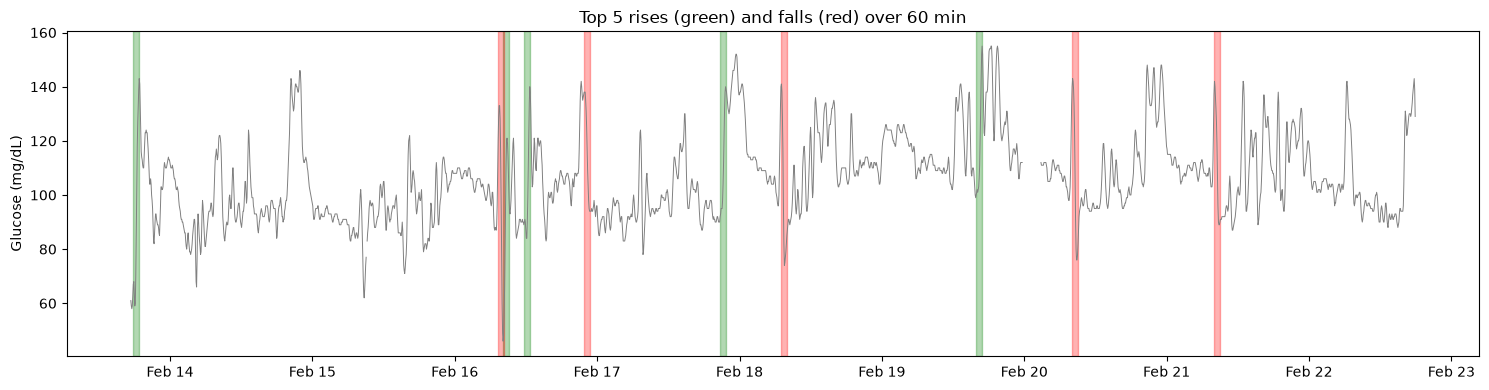

In [20]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(grid.index, grid.values, lw=0.7, color="gray")

for _, e in rises.iterrows():
    ax.axvspan(e["start"], e["end"], color="green", alpha=0.3)
for _, e in falls.iterrows():
    ax.axvspan(e["start"], e["end"], color="red", alpha=0.3)

ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"Top {TOP_N} rises (green) and falls (red) over {WINDOW_MIN} min")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

### Each event up close

Two hours either side of each event. A rise followed by a similar fall is a typical meal response. A fall without a preceding rise might be linked to activity, which you can check later with the HR and accelerometer data.

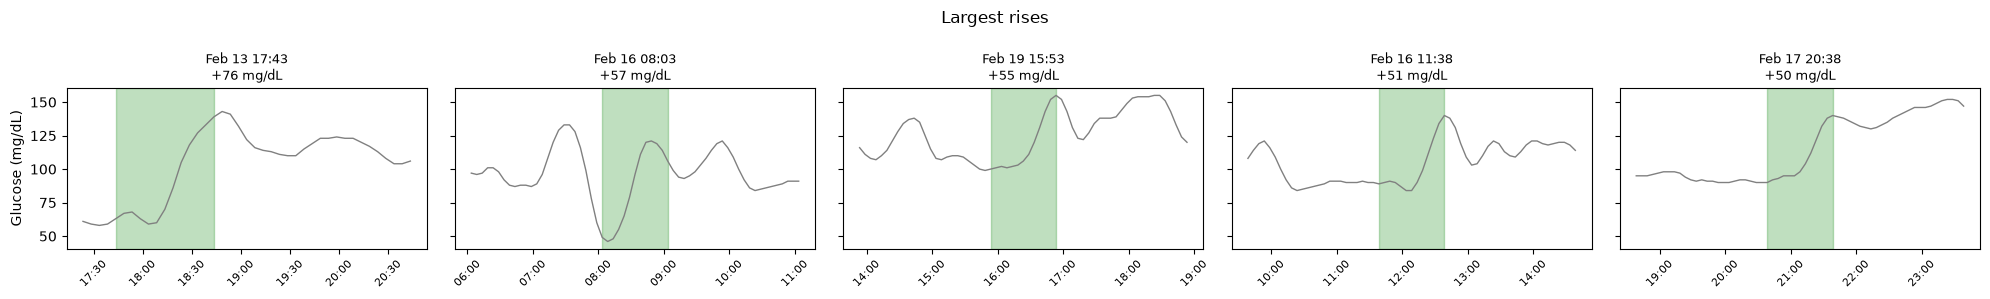

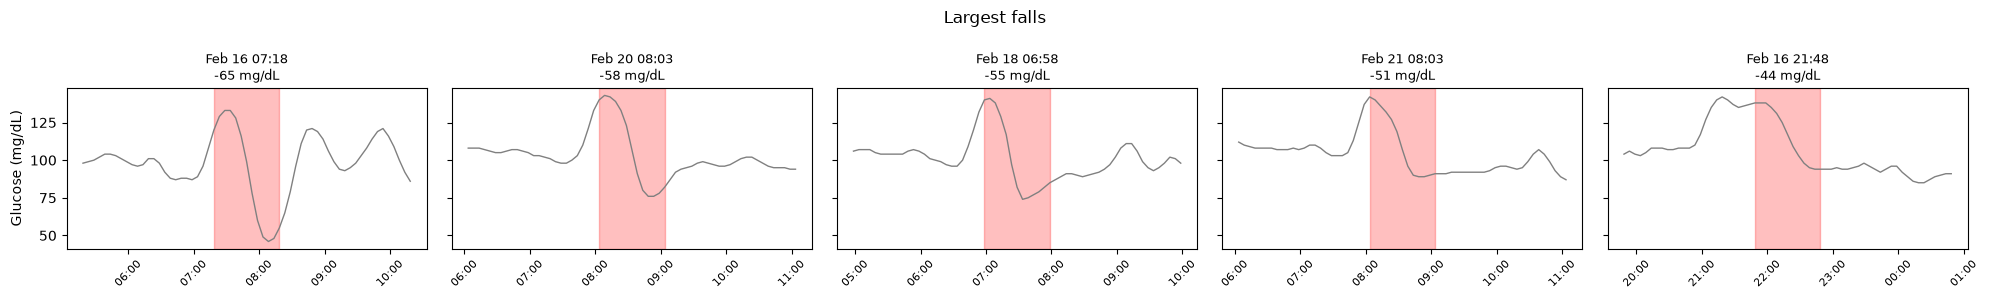

In [21]:
def plot_events(events, title, color):
    fig, axes = plt.subplots(1, len(events), figsize=(4 * len(events), 3), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (_, e) in zip(axes, events.iterrows()):
        win = grid[e["start"] - pd.Timedelta("2h"): e["end"] + pd.Timedelta("2h")]
        ax.plot(win.index, win.values, color="gray", lw=1)
        ax.axvspan(e["start"], e["end"], color=color, alpha=0.25)
        ax.set_title(f"{e['start']:%b %d %H:%M}\n{e['change']:+.0f} mg/dL", fontsize=9)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.tick_params(axis="x", rotation=45, labelsize=8)
    axes[0].set_ylabel("Glucose (mg/dL)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_events(rises, "Largest rises", "green")
plot_events(falls, "Largest falls", "red")

---
## Summary

All Stage 3 answers in one table, also saved as a CSV for comparing participants later.

In [22]:
# Only compare days with at least half a day of data (144 readings)
full_days = daily[daily["count"] >= 144]

summary = pd.Series({
    "SD (mg/dL)": round(sd, 1),
    "CV (%)": round(cv, 1),
    "Stable (CV < 36%)": cv < 36,
    "Most variable full day": str(full_days["CV %"].idxmax()),
    "Least variable full day": str(full_days["CV %"].idxmin()),
    "Mean |rate| (mg/dL/min)": round(rate.abs().mean(), 2),
    "% time steady (±1)": arrows.loc["→ −1 to 1", "% of time"],
    "% time rapid (|rate| > 3)": arrows.loc[["⇊ < −3", "⇈ > 3"], "% of time"].sum(),
    f"Largest {WINDOW_MIN}-min rise (mg/dL)": rises["change"].iloc[0],
    "Largest rise started at": str(rises["start"].iloc[0]),
    f"Largest {WINDOW_MIN}-min fall (mg/dL)": falls["change"].iloc[0],
    "Largest fall started at": str(falls["start"].iloc[0]),
}, name=PID)

summary.to_frame()

,001
SD (mg/dL),15.8
CV (%),14.9
Stable (CV < 36%),True
Most variable full day,2020-02-17
Least variable full day,2020-02-15
Mean |rate| (mg/dL/min),0.43
% time steady (±1),89.4
% time rapid (|rate| > 3),0.4
Largest 60-min rise (mg/dL),76.0
Largest rise started at,2020-02-13 17:43:32


In [24]:
summary.to_frame().T.rename_axis("participant").to_csv(f"stage3_summary_{PID}.csv")
rises.assign(type="rise").pipe(lambda r: pd.concat([r, falls.assign(type="fall")])) \
     .to_csv(f"../clean_data/stage3_events_{PID}.csv", index=False)
print(f"Saved stage3_summary_{PID}.csv and stage3_events_{PID}.csv")

Saved stage3_summary_001.csv and stage3_events_001.csv
